# 02 · IR: Pre-optimized functional-group classifier

Run this notebook after your assistant completes the main IR 01 carpentry workbook, or use a completed reference in `examples/`. Select the dataset by changing only `CARPENTRY_DIR` in the first code cell: the workbook prompt uses `outputs/workshop_carpentry`, while the completed minimal baseline uses `outputs/carpentry`. Keep the model settings fixed when comparing carpentry strategies. It reads three split Parquet files plus their manifest; every preparation must preserve the frozen validation/test files byte-for-byte. This static pipeline retains training-only feature scaling and class weighting, validation-only early stopping and threshold tuning, then one untouched test evaluation.

The model uses the boiling-point module's training template, adapted to multi-label classification: ReLU layers, batch normalization, dropout, AdamW with an initial/maximum learning rate of `1e-5`, cosine annealing with warm restarts, gradient clipping, periodic checkpoints, and a separate post-training loss plot. Class-weighted binary cross-entropy replaces regression MSE.

After 20 epochs, stop only when the last 20 validation losses have a positive slope, that slope stays positive after removing the five highest losses (keeping the original epoch coordinates), and current validation loss exceeds training loss. Both losses are measured in evaluation mode. Restore the minimum-validation-loss checkpoint among epochs with validation loss above training loss; if no epoch qualifies, explicitly fall back to the overall validation minimum. The epoch cap is a resource limit, not evidence of convergence.


Before loading any model data, this notebook enforces `data/frozen_evaluation/evaluation_contract.json`: identical labels, grid and byte-identical validation/test Parquets for every attempt. Signal conversion, cropping, padding and normalization belong in IR 01—not here. The baseline now also excludes training observations of held-out molecules.

### Reading and presenting this notebook

Each code block has a descriptive heading followed by a short explanation labeled **Code Summary:**; saved outputs remain visible. In **VS Code**, open the Command Palette (`Ctrl+Shift+P` on Windows/Linux, `Cmd+Shift+P` on macOS) and choose **Notebook: Collapse All Cell Inputs** (search for `Collapse All Cell Inputs`). Use **Expand All Cell Inputs** to edit, or expand an individual cell using its input control. Do not collapse outputs. VS Code can remember your previous view, so use the command if code is still shown. In **JupyterLab**, code inputs are initially hidden via notebook metadata; expand them with the left-hand cell collapser or the View menu. Hiding code does not disable execution or remove it from the file.


### Load the selected dataset and standardize training inputs

Code Summary: Loads the selected carpentry output and checks its grid, labels, molecular separation, and frozen evaluation files. Fits input standardization on training data only and keeps the training configuration fixed for data comparisons, starting at a learning rate of 1e-5.


In [2]:
from datetime import datetime, timezone
from pathlib import Path
import json
import hashlib
import platform
import random
import sys

# Locate shared helpers without changing the working directory or dataset selector.
MODULE = next((candidate.resolve()
    for parent in (Path.cwd(), *Path.cwd().parents)
    for candidate in (parent, parent / '02_ir_functional_groups')
    if (candidate / 'lib/ir_carpentry.py').is_file()), None)
if MODULE is None:
    raise FileNotFoundError('Open from the workshop, IR module, or its examples folder.')
sys.path.insert(0, str(MODULE / 'lib'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from sklearn.metrics import f1_score, multilabel_confusion_matrix
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torch.utils.tensorboard import SummaryWriter

SEED = 42
MAX_EPOCHS = 2000
LEARNING_RATE = 1e-5
MIN_LEARNING_RATE = 1e-7
WEIGHT_DECAY = 1e-4
COSINE_RESTART_EPOCHS = 20
COSINE_RESTART_MULTIPLIER = 2
VALIDATION_SLOPE_WINDOW = 20
TRIMMED_SLOPE_EXCLUDED_POINTS = 5
GRADIENT_CLIP_NORM = 1.0
SAVE_EVERY_EPOCHS = 25
BATCH_SIZE = 128
torch.set_num_threads(min(4, torch.get_num_threads()))  # Practical, consistent workshop CPU usage.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Change just this directory to select a carpentry dataset (all four files travel together).
CARPENTRY_DIR = Path('outputs/carpentry')  # default: main IR 01
# CARPENTRY_DIR = Path('examples/outputs/01a_omit_transmittance')
# CARPENTRY_DIR = Path('examples/outputs/01b_convert_transmittance')
# CARPENTRY_DIR = Path('examples/outputs/01c_padding_and_quality')
# CARPENTRY_DIR = Path('examples/outputs/01d_resampling_and_balancing')
SPLIT_FILES = {name: MODULE / CARPENTRY_DIR / f'IR_{name}.parquet' for name in ('train', 'validation', 'test')}
MANIFEST_FILE = MODULE / CARPENTRY_DIR / 'data_manifest.json'
if not MANIFEST_FILE.exists() or any(not path.exists() for path in SPLIT_FILES.values()):
    raise FileNotFoundError(f'Run the matching IR 01 or 01a–01d notebook first. Missing split files or data_manifest.json in {CARPENTRY_DIR}.')
data_manifest = json.loads(MANIFEST_FILE.read_text(encoding='utf-8'))
LABELS = data_manifest['labels']
FEATURE_COUNT = int(data_manifest['feature_count'])
TARGET_GRID = np.asarray(data_manifest['wavenumber'], dtype=np.float32)
from ir_carpentry import validate_frozen_evaluation, training_pool
evaluation_contract = validate_frozen_evaluation(MODULE, MODULE / CARPENTRY_DIR, TARGET_GRID)
if LABELS != evaluation_contract['labels']:
    raise ValueError('Dataset label order differs from the frozen evaluation contract.')
print('PASS: validation/test files and spectral grid match the frozen evaluation reference.')
if len(TARGET_GRID) != FEATURE_COUNT:
    raise ValueError('The carpentry manifest has an inconsistent feature_count and wavenumber grid.')

def load_and_validate_split(name, path):
    frame = pd.read_parquet(path)
    required = {'NIST_molecule', 'CAS_NO', 'IR', 'wavenumber'} | set(LABELS)
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f'{name} is missing required columns: {sorted(missing)}')
    features = np.vstack(frame.IR.map(lambda values: np.asarray(values, dtype=np.float32)))
    grids_match = frame.wavenumber.map(lambda values: np.array_equal(np.asarray(values, dtype=np.float32), TARGET_GRID)).all()
    targets = frame[LABELS].to_numpy()
    if features.shape != (len(frame), FEATURE_COUNT) or not np.isfinite(features).all():
        raise ValueError(f'{name} does not contain finite {FEATURE_COUNT}-point IR arrays.')
    if not grids_match or not np.isfinite(targets).all() or not np.isin(targets, [0, 1]).all():
        raise ValueError(f'{name} does not match the manifest grid or has non-binary labels.')
    return frame, features, targets.astype(np.int64)

train_frame, X_train_raw, y_train = load_and_validate_split('train', SPLIT_FILES['train'])
validation_frame, X_validation_raw, y_validation = load_and_validate_split('validation', SPLIT_FILES['validation'])
test_frame, X_test_raw, y_test = load_and_validate_split('test', SPLIT_FILES['test'])
_, overlapping_training_observations = training_pool(train_frame, {'validation': validation_frame, 'test': test_frame})
if overlapping_training_observations:
    raise ValueError('Training includes held-out molecular identities; rerun IR 01 carpentry.')
for identifier in ('NIST_molecule', 'CAS_NO'):
    split_ids = [set(frame[identifier]) for frame in (train_frame, validation_frame, test_frame)]
    if any(left & right for index, left in enumerate(split_ids) for right in split_ids[index + 1:]):
        raise ValueError(f'{identifier} appears in more than one split; rerun IR 1.')
if (y_train.sum(axis=0) == 0).any():
    absent = np.asarray(LABELS)[y_train.sum(axis=0) == 0].tolist()
    raise ValueError(f'Training labels without a positive example: {absent}. Adjust carpentry before training.')

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_validation = scaler.transform(X_validation_raw).astype(np.float32)
X_test = scaler.transform(X_test_raw).astype(np.float32)
print(f'Device: {DEVICE}; features: {FEATURE_COUNT}; labels: {len(LABELS)}')
print(f'Train/validation/test rows: {len(train_frame):,} / {len(validation_frame):,} / {len(test_frame):,}')
print('Carpentry choices:', data_manifest['carpentry'])

PASS: validation/test files and spectral grid match the frozen evaluation reference.


Device: cpu; features: 500; labels: 12
Train/validation/test rows: 4,848 / 975 / 975
Carpentry choices: {'signal_policy': 'as_recorded', 'bounds_policy': 'require_full_coverage', 'resampling': 'linear', 'normalization': 'per_spectrum_minmax', 'cleansing': 'none', 'training_identity_guard': True, 'description': 'naive numeric baseline; no advanced carpentry'}


### Define the classifier and configure optimization

Code Summary: Builds the multi-label neural classifier and configures class-weighted binary cross-entropy, AdamW, and cosine warm restarts. Creates an experiment folder, TensorBoard log, and settings record before training.


In [3]:
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN_DIR = MODULE / 'outputs/optimized_training' / f'run_{RUN_ID}'
CHECKPOINT_DIR = RUN_DIR / 'checkpoints'
TENSORBOARD_DIR = RUN_DIR / 'tensorboard'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=False)
BEST_CHECKPOINT = RUN_DIR / 'best_validation_model.pt'
RUN_DOCUMENTATION = RUN_DIR / 'run_documentation.json'

class SpectralMLP(nn.Module):
    def __init__(self, inputs, outputs):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(inputs, 256), nn.ReLU(), nn.BatchNorm1d(256), nn.Dropout(0.25),
            nn.Linear(256, 128), nn.ReLU(), nn.BatchNorm1d(128), nn.Dropout(0.15),
            nn.Linear(128, outputs),
        )

    def forward(self, inputs):
        return self.network(inputs)

generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train.astype(np.float32))),
    batch_size=BATCH_SIZE, shuffle=True, generator=generator,
)
validation_features = torch.from_numpy(X_validation).to(DEVICE)
validation_targets = torch.from_numpy(y_validation.astype(np.float32)).to(DEVICE)
positive = y_train.sum(axis=0)
negative = len(y_train) - positive
pos_weight = torch.tensor(np.clip(negative / np.maximum(positive, 1), 1, 20), dtype=torch.float32, device=DEVICE)
model = SpectralMLP(FEATURE_COUNT, len(LABELS)).to(DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=COSINE_RESTART_EPOCHS, T_mult=COSINE_RESTART_MULTIPLIER, eta_min=MIN_LEARNING_RATE
)
writer = SummaryWriter(log_dir=str(TENSORBOARD_DIR))

def robust_validation_slopes(losses):
    losses = np.asarray(losses, dtype=float)
    if losses.shape != (VALIDATION_SLOPE_WINDOW,) or not np.isfinite(losses).all():
        raise ValueError('A slope check requires one complete, finite 20-epoch window.')
    if not 0 <= TRIMMED_SLOPE_EXCLUDED_POINTS < len(losses) - 1:
        raise ValueError('Trimming must leave at least two loss values.')
    coordinates = np.arange(len(losses), dtype=float)
    keep = np.ones(len(losses), dtype=bool)
    if TRIMMED_SLOPE_EXCLUDED_POINTS:
        keep[np.argsort(losses, kind='stable')[-TRIMMED_SLOPE_EXCLUDED_POINTS:]] = False
    return (float(np.polyfit(coordinates, losses, 1)[0]),
            float(np.polyfit(coordinates[keep], losses[keep], 1)[0]))

run_documentation = {
    'data_directory': CARPENTRY_DIR.as_posix(),
    'data_files_sha256': {name: hashlib.sha256(path.read_bytes()).hexdigest() for name, path in SPLIT_FILES.items()},
    'torch_num_threads': torch.get_num_threads(),
    'run_id': RUN_ID, 'created_utc': datetime.now(timezone.utc).isoformat(), 'device': str(DEVICE),
    'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'torch': torch.__version__,
    'data_manifest': data_manifest,
    'model': str(model),
    'training': {'seed': SEED, 'max_epochs': MAX_EPOCHS, 'learning_rate': LEARNING_RATE,
                 'batch_size': BATCH_SIZE, 'optimizer': f'AdamW(lr={LEARNING_RATE}, weight_decay={WEIGHT_DECAY})',
                 'scheduler': {'name': 'CosineAnnealingWarmRestarts', 'T_0': COSINE_RESTART_EPOCHS,
                               'T_mult': COSINE_RESTART_MULTIPLIER, 'eta_min': MIN_LEARNING_RATE},
                 'early_stopping': {'window': VALIDATION_SLOPE_WINDOW, 'remove_highest': TRIMMED_SLOPE_EXCLUDED_POINTS,
                                    'rule': 'raw slope > 0 AND trimmed slope > 0 AND validation loss > train loss'},
                 'selection': 'minimum validation loss where validation exceeds eval-mode training loss; global-minimum fallback',
                 'gradient_clip_norm': GRADIENT_CLIP_NORM, 'loss_measurement': 'eval mode; sample-weighted means',
                 'loss': 'BCEWithLogitsLoss(class-weighted)', 'checkpoint_every_epochs': SAVE_EVERY_EPOCHS}
}
RUN_DOCUMENTATION.write_text(json.dumps(run_documentation, indent=2), encoding='utf-8')
writer.add_text('model', str(model), 0)
writer.add_text('configuration', json.dumps(run_documentation['training'], indent=2), 0)
print(f'Run directory: {RUN_DIR}')
print(f'TensorBoard: tensorboard --logdir {TENSORBOARD_DIR}')


Run directory: outputs\optimized_training\run_20261019T231316873488Z
TensorBoard: tensorboard --logdir outputs\optimized_training\run_20261019T231316873488Z\tensorboard


### Train with robust stopping and checkpoint selection

Code Summary: Trains the classifier, saves periodic checkpoints, and monitors comparable training/validation losses. Stopping requires rising 20-epoch validation trends both with and without the five highest losses, with validation loss above training loss. Restores the lowest eligible validation-loss model or the documented fallback, and reports any epoch-limit stop.


In [4]:
@torch.inference_mode()
def evaluation_loss(features, targets):
    """Use identical eval-mode, class-weighted BCE for training and validation."""
    model.eval()
    total_loss, total_rows = 0.0, 0
    for start in range(0, len(features), BATCH_SIZE):
        batch_features = features[start:start + BATCH_SIZE].to(DEVICE)
        batch_targets = targets[start:start + BATCH_SIZE].to(DEVICE)
        total_loss += criterion(model(batch_features), batch_targets).item() * len(batch_targets)
        total_rows += len(batch_targets)
    return total_loss / total_rows

training_features = torch.from_numpy(X_train)
training_targets = torch.from_numpy(y_train.astype(np.float32))
FALLBACK_CHECKPOINT = RUN_DIR / 'overall_validation_minimum.pt'
best_eligible_loss = overall_best_loss = float('inf')
best_eligible_epoch = None
history = []
stopped_by_slope_rule = False

for epoch in range(1, MAX_EPOCHS + 1):
    scheduler.step(epoch - 1)
    learning_rate = optimizer.param_groups[0]['lr']
    model.train()
    fit_loss_sum, fit_rows = 0.0, 0
    for features, targets in train_loader:
        features, targets = features.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(features), targets)
        if not torch.isfinite(loss):
            raise FloatingPointError(f'Nonfinite training loss at epoch {epoch}.')
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
        optimizer.step()
        fit_loss_sum += loss.item() * len(targets)
        fit_rows += len(targets)

    train_loss = evaluation_loss(training_features, training_targets)
    validation_loss = evaluation_loss(validation_features, validation_targets)
    if not np.isfinite([train_loss, validation_loss]).all():
        raise FloatingPointError(f'Nonfinite evaluation loss at epoch {epoch}.')
    raw_slope = trimmed_slope = float('nan')
    if len(history) + 1 >= VALIDATION_SLOPE_WINDOW:
        recent = [record['validation loss'] for record in history[-(VALIDATION_SLOPE_WINDOW - 1):]]
        raw_slope, trimmed_slope = robust_validation_slopes(recent + [validation_loss])
    history.append({'epoch': epoch, 'train loss': train_loss, 'validation loss': validation_loss,
                    'learning rate': learning_rate, 'train fit loss': fit_loss_sum / fit_rows,
                    'raw validation slope': raw_slope, 'trimmed validation slope': trimmed_slope})
    writer.add_scalar('loss/train', train_loss, epoch)
    writer.add_scalar('loss/validation', validation_loss, epoch)
    writer.add_scalar('loss/train_fit_dropout_enabled', fit_loss_sum / fit_rows, epoch)
    writer.add_scalar('learning_rate', learning_rate, epoch)
    if np.isfinite(raw_slope):
        writer.add_scalar('slope/raw', raw_slope, epoch)
        writer.add_scalar('slope/trimmed', trimmed_slope, epoch)

    checkpoint_payload = {
        'state_dict': model.state_dict(), 'labels': LABELS, 'feature_count': FEATURE_COUNT,
        'wavenumber': TARGET_GRID.tolist(), 'scaler_mean': scaler.mean_.tolist(),
        'scaler_scale': scaler.scale_.tolist(), 'epoch': epoch,
        'validation_loss': validation_loss, 'train_loss': train_loss,
        'learning_rate': learning_rate,
    }
    if epoch % SAVE_EVERY_EPOCHS == 0:
        torch.save(checkpoint_payload, CHECKPOINT_DIR / f'epoch_{epoch:03d}.pt')
    if validation_loss < overall_best_loss:
        overall_best_loss = validation_loss
        torch.save(checkpoint_payload, FALLBACK_CHECKPOINT)
    if validation_loss > train_loss and validation_loss < best_eligible_loss:
        best_eligible_loss = validation_loss
        best_eligible_epoch = epoch
        torch.save(checkpoint_payload, BEST_CHECKPOINT)
    if epoch == 1 or epoch % 100 == 0:
        print(f'Epoch {epoch:4d}: train={train_loss:.4f}, validation={validation_loss:.4f}, lr={learning_rate:.2e}')
    # Persist progress for long runner jobs; plots stay in the following cell.
    if epoch % 20 == 0:
        pd.DataFrame(history).to_csv(RUN_DIR / 'training_history.csv', index=False)
    if raw_slope > 0 and trimmed_slope > 0 and validation_loss > train_loss:
        stopped_by_slope_rule = True
        print(f'Stopping at epoch {epoch}: raw 20-epoch slope={raw_slope:.6g}; '
              f'after removing the five highest losses={trimmed_slope:.6g}; validation exceeds training loss.')
        break

history_frame = pd.DataFrame(history)
history_frame.to_csv(RUN_DIR / 'training_history.csv', index=False)
selection_fallback = best_eligible_epoch is None
if selection_fallback:
    fallback = torch.load(FALLBACK_CHECKPOINT, map_location='cpu', weights_only=True)
    torch.save(fallback, BEST_CHECKPOINT)
    print('No epoch had validation loss above training loss; using the overall validation minimum.')
best_checkpoint = torch.load(BEST_CHECKPOINT, map_location=DEVICE, weights_only=True)
model.load_state_dict(best_checkpoint['state_dict'])
stop_reason = 'robust_validation_slope' if stopped_by_slope_rule else 'maximum_epochs'
if not stopped_by_slope_rule:
    print(f'Reached the {MAX_EPOCHS}-epoch cap; the requested convergence rule did not trigger.')
display(HTML(f'<strong>IR training complete</strong><br>'
             f'<progress value="{len(history)}" max="{MAX_EPOCHS}" style="width:22rem"></progress> '
             f'{len(history)}/{MAX_EPOCHS} epochs'))
print(f"Restored selected model: epoch {best_checkpoint['epoch']} "
      f"(validation loss={best_checkpoint['validation_loss']:.4f}).")
writer.flush()


Epoch    1: train=1.0973, validation=1.0824, lr=1.00e-05


Epoch  100: train=0.6531, validation=0.6615, lr=5.24e-06


Epoch  200: train=0.5554, validation=0.5761, lr=7.03e-06


Stopping at epoch 288: raw 20-epoch slope=3.78765e-05; after removing the five highest losses=3.0868e-05; validation exceeds training loss.


Restored selected model: epoch 272 (validation loss=0.5432).


### Select thresholds and evaluate functional-group predictions

Code Summary: Selects classification thresholds on validation data, evaluates the restored model on the test set, and plots training histories and functional-group scores. Saves the model, scaling, thresholds, predictions, and metrics for comparison.


,label,validation_threshold,test_support,true_negative,false_positive,false_negative,true_positive,test_precision,test_recall,test_specificity,test_F1,test_accuracy,test_balanced_accuracy
0,Vinylic,0.66,150,744,81,26,124,0.605,0.827,0.902,0.699,0.890,0.864
1,Arene,0.36,531,376,68,21,510,0.882,0.960,0.847,0.920,0.909,0.904
2,Alcohol,0.66,245,697,33,21,224,0.872,0.914,0.955,0.892,0.945,0.935
3,Ether,0.63,265,692,18,25,240,0.930,0.906,0.975,0.918,0.956,0.940
4,Amine,0.84,104,857,14,25,79,0.849,0.760,0.984,0.802,0.960,0.872
5,Nitrile,0.81,44,898,33,22,22,0.400,0.500,0.965,0.444,0.944,0.732
6,Aldehyde,0.83,26,946,3,5,21,0.875,0.808,0.997,0.840,0.992,0.902
7,Ketone,0.89,93,857,25,22,71,0.740,0.763,0.972,0.751,0.952,0.868
8,CarboxylAcid,0.90,69,900,6,11,58,0.906,0.841,0.993,0.872,0.983,0.917
9,Ester,0.85,118,844,13,8,110,0.894,0.932,0.985,0.913,0.978,0.959


Untouched test metrics — macro F1: 0.773; micro F1: 0.850; exact-match accuracy: 0.642


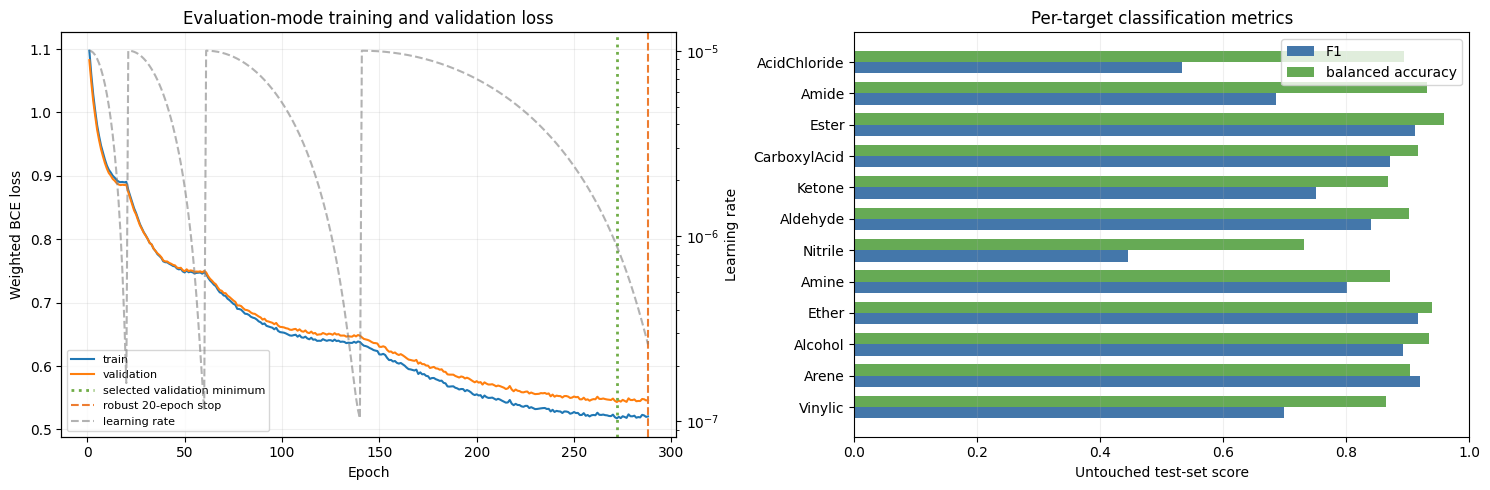

Saved model, metrics, predictions, plot, TensorBoard log, and documentation under outputs\optimized_training\run_20261019T231316873488Z.


In [5]:
def probabilities(features):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(features).to(DEVICE))).cpu().numpy()

validation_probability = probabilities(X_validation)
test_probability = probabilities(X_test)
threshold_grid = np.linspace(0.10, 0.90, 81)
thresholds = np.array([
    threshold_grid[np.argmax([f1_score(y_validation[:, index], validation_probability[:, index] >= threshold, zero_division=0)
                                  for threshold in threshold_grid])]
    for index in range(len(LABELS))
])
test_prediction = (test_probability >= thresholds).astype(int)
validation_macro_f1 = f1_score(y_validation, validation_probability >= thresholds, average='macro', zero_division=0)
confusion = multilabel_confusion_matrix(y_test, test_prediction)
tn, fp, fn, tp = (confusion[:, 0, 0], confusion[:, 0, 1], confusion[:, 1, 0], confusion[:, 1, 1])
precision = tp / np.maximum(tp + fp, 1)
recall = tp / np.maximum(tp + fn, 1)
specificity = tn / np.maximum(tn + fp, 1)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
accuracy = (tp + tn) / np.maximum(tp + tn + fp + fn, 1)
balanced_accuracy = (recall + specificity) / 2
summary = pd.DataFrame({
    'label': LABELS, 'validation_threshold': thresholds, 'test_support': y_test.sum(axis=0),
    'true_negative': tn, 'false_positive': fp, 'false_negative': fn, 'true_positive': tp,
    'test_precision': precision, 'test_recall': recall, 'test_specificity': specificity,
    'test_F1': f1, 'test_accuracy': accuracy, 'test_balanced_accuracy': balanced_accuracy,
})
macro_f1 = f1_score(y_test, test_prediction, average='macro', zero_division=0)
micro_f1 = f1_score(y_test, test_prediction, average='micro', zero_division=0)
subset_accuracy = float(np.mean(np.all(y_test == test_prediction, axis=1)))
display(summary.round(3))
print(f'Untouched test metrics — macro F1: {macro_f1:.3f}; micro F1: {micro_f1:.3f}; exact-match accuracy: {subset_accuracy:.3f}')

summary.to_csv(RUN_DIR / 'test_metrics_by_label.csv', index=False)
predictions = test_frame[['NIST_molecule', 'CAS_NO', 'Name', 'SMILES']].copy()
for index, label in enumerate(LABELS):
    predictions[f'{label}_actual'] = y_test[:, index]
    predictions[f'{label}_probability'] = test_probability[:, index]
    predictions[f'{label}_prediction'] = test_prediction[:, index]
predictions.to_parquet(RUN_DIR / 'test_predictions.parquet', index=False)

model_bundle = {**best_checkpoint, 'thresholds': thresholds.tolist(),
                'run_documentation': str(RUN_DOCUMENTATION), 'test_macro_f1': float(macro_f1)}
torch.save(model_bundle, RUN_DIR / 'ir_functional_group_classifier.pt')
run_documentation['results'] = {'best_epoch': int(best_checkpoint['epoch']), 'best_validation_loss': float(best_checkpoint['validation_loss']),
                                'epochs_run': len(history), 'stop_reason': stop_reason,
                                'selection_fallback': selection_fallback, 'overall_lowest_validation_loss': overall_best_loss,
                                'selected_train_loss': float(best_checkpoint['train_loss']),
                                'final_raw_validation_slope': raw_slope, 'final_trimmed_validation_slope': trimmed_slope,
                                'validation_macro_f1': float(validation_macro_f1),
                                'test_macro_f1': float(macro_f1), 'test_micro_f1': float(micro_f1),
                                'test_exact_match_accuracy': subset_accuracy}
RUN_DOCUMENTATION.write_text(json.dumps(run_documentation, indent=2), encoding='utf-8')
writer.add_scalar('metrics/test_macro_f1', macro_f1, best_checkpoint['epoch'])
writer.add_scalar('metrics/test_micro_f1', micro_f1, best_checkpoint['epoch'])
writer.flush(); writer.close()

history_frame = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(history_frame.epoch, history_frame['train loss'], label='train')
axes[0].plot(history_frame.epoch, history_frame['validation loss'], label='validation')
axes[0].axvline(best_checkpoint['epoch'], color='#70AD47', ls=':', lw=2, label='selected validation minimum')
if stopped_by_slope_rule:
    axes[0].axvline(len(history), color='#ED7D31', ls='--', lw=1.5, label='robust 20-epoch stop')
lr_axis = axes[0].twinx()
lr_axis.plot(history_frame.epoch, history_frame['learning rate'], color='gray', ls='--', alpha=.6, label='learning rate')
lr_axis.set(yscale='log', ylabel='Learning rate')
handles, labels = axes[0].get_legend_handles_labels()
lr_handles, lr_labels = lr_axis.get_legend_handles_labels()
axes[0].legend(handles + lr_handles, labels + lr_labels, fontsize=8)
axes[0].set(title='Evaluation-mode training and validation loss', xlabel='Epoch', ylabel='Weighted BCE loss'); axes[0].grid(alpha=0.2)
position = np.arange(len(LABELS))
axes[1].barh(position - 0.18, summary['test_F1'], height=0.36, label='F1', color='#4477AA')
axes[1].barh(position + 0.18, summary['test_balanced_accuracy'], height=0.36, label='balanced accuracy', color='#66AA55')
axes[1].set(yticks=position, yticklabels=LABELS, xlim=(0, 1), xlabel='Untouched test-set score', title='Per-target classification metrics')
axes[1].legend(); axes[1].grid(axis='x', alpha=0.2)
fig.tight_layout(); fig.savefig(RUN_DIR / 'model_summary.png', dpi=160, bbox_inches='tight'); plt.show()
print(f'Saved model, metrics, predictions, plot, TensorBoard log, and documentation under {RUN_DIR}.')


## Classify an uploaded IR spectrum

Use the upload control below after training. Upload either a CSV with one row per point and `wavenumber` plus `IR` columns, or a one-row Parquet file whose `wavenumber` and `IR` columns contain arrays. The spectrum must cover the full wavenumber range recorded in the carpentry manifest. The notebook regrids it to the training grid without extrapolating, then reports predicted functional groups and probabilities using the validation-selected thresholds.

A prediction is a model result, not structural proof. Inspect the spectrum and its probabilities, especially for rare labels or spectra collected with a different instrument/preprocessing protocol.


### Classify an uploaded prepared spectrum

Code Summary: Classifies an uploaded CSV or Parquet spectrum using the trained model. Signals must already match the chosen carpentry preparation; this helper only regrids and scales them, rejecting spectra that do not cover the required coordinate range.


In [6]:
from io import BytesIO
import ipywidgets as widgets

def uploaded_arrays(table):
    columns = {str(column).casefold(): column for column in table.columns}
    if 'wavenumber' not in columns or 'ir' not in columns:
        raise ValueError('Uploaded data need columns named wavenumber and IR (case-insensitive).')
    grid_column, signal_column = columns['wavenumber'], columns['ir']
    first_grid, first_signal = table[grid_column].iloc[0], table[signal_column].iloc[0]
    if isinstance(first_grid, (list, tuple, np.ndarray)) and isinstance(first_signal, (list, tuple, np.ndarray)):
        grid, signal = np.asarray(first_grid, dtype=float), np.asarray(first_signal, dtype=float)
    else:
        grid, signal = table[grid_column].to_numpy(dtype=float), table[signal_column].to_numpy(dtype=float)
    if grid.ndim != 1 or signal.ndim != 1 or len(grid) != len(signal) or len(grid) < 2:
        raise ValueError('The uploaded IR and wavenumber arrays must be finite, one-dimensional, and equally long.')
    order = np.argsort(grid); grid, signal = grid[order], signal[order]
    grid, inverse = np.unique(grid, return_inverse=True)
    signal = np.bincount(inverse, weights=signal) / np.bincount(inverse)
    if not (np.isfinite(grid).all() and np.isfinite(signal).all()):
        raise ValueError('The uploaded spectrum contains non-finite values.')
    if grid.min() > TARGET_GRID.min() or grid.max() < TARGET_GRID.max():
        raise ValueError('The uploaded spectrum does not cover the full training wavenumber range; it will not be extrapolated.')
    return np.interp(TARGET_GRID, grid, signal).astype(np.float32)

upload = widgets.FileUpload(accept='.csv,.parquet', multiple=False, description='Upload IR')
upload_output = widgets.Output()

def classify_upload(change):
    if not upload.value:
        return
    uploaded = next(iter(upload.value))
    name, content = uploaded['name'], uploaded['content']
    with upload_output:
        upload_output.clear_output(wait=True)
        try:
            table = pd.read_parquet(BytesIO(content)) if name.lower().endswith('.parquet') else pd.read_csv(BytesIO(content))
            spectrum = uploaded_arrays(table)
            probability = probabilities(scaler.transform(spectrum.reshape(1, -1)).astype(np.float32))[0]
            result = pd.DataFrame({'functional group': LABELS, 'probability': probability, 'threshold': thresholds,
                                   'present': probability >= thresholds})
            display(result.sort_values('probability', ascending=False).round(3))
        except Exception as error:
            print(f'Could not classify {name}: {error}')

upload.observe(classify_upload, names='value')
display(widgets.VBox([widgets.HTML('<b>Upload an IR CSV or Parquet file</b>'), upload, upload_output]))


Each execution gets a timestamped folder under `outputs/optimized_training/`, so the model, scaler, thresholds, metrics, predictions, plot, checkpoints, TensorBoard events, and machine-readable run documentation remain connected to the carpentry artifact that produced them.
